<a href="https://colab.research.google.com/github/Egorch-max/ML-2026-Frolov/blob/main/hw2_knn_Frolov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ 2. Предсказание цены аренды жилья на Airbnb (Болонья)
**Фролов Егор, 3823Б1ПМоп2**

Данные: [Inside Airbnb](https://insideairbnb.com/get-the-data/), Bologna, `listings.csv.gz` (Detailed Listings, 26.06.2026).

## 0. Постановка задачи

Каждый объект - объявление о сдаче жилья в Болонье на Airbnb. Признаки описывают само жильё (число гостей, спален, ванных, тип жилья, район, координаты, удобства), хозяина (суперхост, сколько у него объявлений, сколько лет на Airbnb), отзывы (количество, оценки) и доступность в календаре.

**Задача - регрессия:** по характеристикам объявления предсказать цену аренды за ночь `price` (в евро).

Практический смысл: подсказать хозяину справедливую цену для нового объявления или найти объявления с завышенной/заниженной ценой.

Качество будем измерять:
- **MAE** - средняя абсолютная ошибка в евро (основная метрика, понятная «на пальцах»);
- **RMSE** - корень из среднеквадратичной ошибки (сильнее штрафует большие промахи);
- **R²** - доля объяснённой дисперсии (1 - идеально, 0 - не лучше константы).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline

## 1. Читаем данные

In [2]:
url = 'https://data.insideairbnb.com/italy/emilia-romagna/bologna/2026-06-26/data/listings.csv.gz'
data_raw = pd.read_csv(url)
# если ссылка не работает - загрузить файл в Colab и указать путь:
# data_raw = pd.read_csv('listings.csv.gz')
print(data_raw.shape)

(4948, 90)


In [3]:
data_raw.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,46352,https://www.airbnb.com/rooms/46352,20260626225529,2026-06-27,city scrape,A room in Pasolini's house,"Simple, cozy and silent room in a lived house ...",NaN,https://a0.muscache.com/pictures/9f94acc3-98fc...,467810,...,4.86,4.84,4.68,IT037006C1C1767,NaN,2,0,2,0,2.59
1,59697,https://www.airbnb.com/rooms/59697,20260626225529,2026-06-27,city scrape,COZY LARGE BEDROOM in the city center,"Cozy, spacious and bright double bedroom, in a...",NaN,https://a0.muscache.com/pictures/ac0528c4-b26f...,286688,...,4.80,4.83,4.66,NaN,NaN,2,0,2,0,1.47
2,85368,https://www.airbnb.com/rooms/85368,20260626225529,2026-06-27,city scrape,Garden House Bologna,NaN,NaN,https://a0.muscache.com/pictures/585815/331d45...,467675,...,4.99,4.83,4.83,IT037006C2QKQSH3S7,NaN,1,1,0,0,0.41
3,219878,https://www.airbnb.com/rooms/219878,20260626225529,2026-06-27,city scrape,Top floor with elevator for Long and Short Stays,"Bright, quiet apartment with a private office ...",NaN,https://a0.muscache.com/pictures/f16e5b7e-68b3...,1139326,...,4.93,4.85,4.78,IT037006C2HQERHOGR,NaN,1,1,0,0,1.11
4,229114,https://www.airbnb.com/rooms/229114,20260626225529,2026-06-27,city scrape,Apartment with terrace between center and fair,"Bright apartment for 4 people in Bologna, conv...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,1196205,...,4.95,4.53,4.71,IT037006C2KRRTWGRT,NaN,1,1,0,0,0.67


Целевая переменная `price` записана строкой (`$66.50`), переводим её в число. Объявления без цены удаляем: для обучения и проверки нужен ответ.

In [4]:
data = data_raw.copy()

# целевая переменная: цена за ночь, строка вида '$1,234.00' -> число
data['price'] = data['price'].str.replace(r'[$,]', '', regex=True).astype(float)
print('Объявлений без цены:', data['price'].isna().sum())
data = data.dropna(subset=['price']).reset_index(drop=True)
print('Осталось объектов:', data.shape[0])

Объявлений без цены: 404
Осталось объектов: 4544


### Отбор и подготовка признаков

Из 90 столбцов отбрасываем:
- полностью пустые (`neighborhood_overview`, `host_since`, `host_response_rate` и др.);
- служебные - id, ссылки, дата выгрузки, имя хозяина: уникальны для каждой строки и не влияют на цену, модель бы их просто «запомнила»;
- столбцы с **утечкой** цены (`price_quote_*`, `estimated_revenue_l365d`) - в них цена уже зашита.

Из «неудобных» признаков делаем числовые:
- `bathrooms_text` (`'1.5 shared baths'`) → число ванных (заполняет пропуски в `bathrooms`) и флаг «ванная общая»;
- `amenities` (список удобств) → количество удобств;
- даты первого/последнего отзыва → сколько дней прошло;
- текст `description` → длина описания в словах. Сам текст метод ближайших соседей использовать не умеет, для этого нужна отдельная векторизация (TF-IDF и т.п.).

У `property_type` 43 значения, многие редкие - оставляем 8 частых, остальные объединяем в `Other`.

In [5]:
scrape_date = pd.to_datetime(data['last_scraped']).max()

# число ванных и «общая ли ванная» из текстового поля bathrooms_text ('1.5 shared baths', 'Half-bath', ...)
bt = data['bathrooms_text'].fillna('').str.lower()
bath_num = bt.str.extract(r'([\d.]+)')[0].astype(float)
bath_num[bt.str.contains('half')] = 0.5
data['bathrooms'] = data['bathrooms'].fillna(bath_num)
data['bath_shared'] = np.where(bt.str.contains('shared'), 't', 'f')

# список удобств -> их количество
data['amenities_count'] = data['amenities'].str.count('"') // 2

# даты -> «сколько дней прошло»
data['days_since_first_review'] = (scrape_date - pd.to_datetime(data['first_review'])).dt.days
data['days_since_last_review']  = (scrape_date - pd.to_datetime(data['last_review'])).dt.days

# текст -> длина описания в словах
data['description_len'] = data['description'].fillna('').str.split().str.len()

# тип жилья: оставляем 8 самых частых значений, остальное -> 'Other'
top_types = data['property_type'].value_counts().index[:8]
data['property_type'] = data['property_type'].where(data['property_type'].isin(top_types), 'Other')

numerical_columns = ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude',
    'minimum_nights', 'maximum_nights',
    'availability_30', 'availability_60', 'availability_90', 'availability_365',
    'number_of_reviews', 'number_of_reviews_ltm', 'reviews_per_month', 'estimated_occupancy_l365d',
    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
    'review_scores_communication', 'review_scores_location', 'review_scores_value',
    'host_listings_count', 'calculated_host_listings_count', 'hosts_time_as_host_years',
    'amenities_count', 'days_since_first_review', 'days_since_last_review', 'description_len']
categorical_columns = ['room_type', 'neighbourhood_cleansed', 'property_type',
    'bath_shared', 'host_is_superhost', 'host_identity_verified', 'has_availability']

data = data[numerical_columns + categorical_columns + ['price']]
print(data.shape)

(4544, 38)


## 2. Разбиваем на обучающую и тестовую выборки

Разбиваем **сразу**, до любой обработки: медианы для пропусков, пороги для выбросов, средние для нормализации будем считать **только по train**, чтобы информация из теста не «подглядывалась» при обучении. 75% - train, 25% - test.

In [6]:
from sklearn.model_selection import train_test_split

data_train, data_test = train_test_split(data, test_size=0.25, random_state=42)
data_train = data_train.copy(); data_test = data_test.copy()
print('train:', data_train.shape, ' test:', data_test.shape)

train: (3408, 38)  test: (1136, 38)


## 3. Визуализация и основные характеристики (по train)

In [7]:
data_train[numerical_columns + ['price']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
accommodates,3408.0,3.62,1.74,1.00,2.00,4.00,4.00,16.00
bedrooms,2803.0,1.47,0.75,1.00,1.00,1.00,2.00,12.00
beds,3225.0,2.18,1.31,1.00,1.00,2.00,3.00,20.00
bathrooms,3407.0,1.19,0.53,0.00,1.00,1.00,1.00,12.00
latitude,3408.0,44.50,0.01,44.45,44.49,44.50,44.50,44.55
longitude,3408.0,11.34,0.02,11.24,11.34,11.34,11.35,11.42
minimum_nights,3405.0,4.27,9.39,1.00,1.00,1.00,2.00,90.00
maximum_nights,3405.0,549.17,466.16,3.00,40.00,365.00,1125.00,1125.00
availability_30,3408.0,15.19,9.35,0.00,7.00,15.00,23.00,30.00
availability_60,3408.0,33.85,17.51,0.00,21.00,34.00,49.00,60.00


In [8]:
data_train[categorical_columns].describe()

,room_type,neighbourhood_cleansed,property_type,bath_shared,host_is_superhost,host_identity_verified,has_availability
count,3408,3408,3408,3408,3402,3402,3408
unique,4,6,9,2,2,2,2
top,Entire home/apt,Santo Stefano,Entire rental unit,f,f,t,t
freq,2698,1216,1400,3195,2150,3400,3273


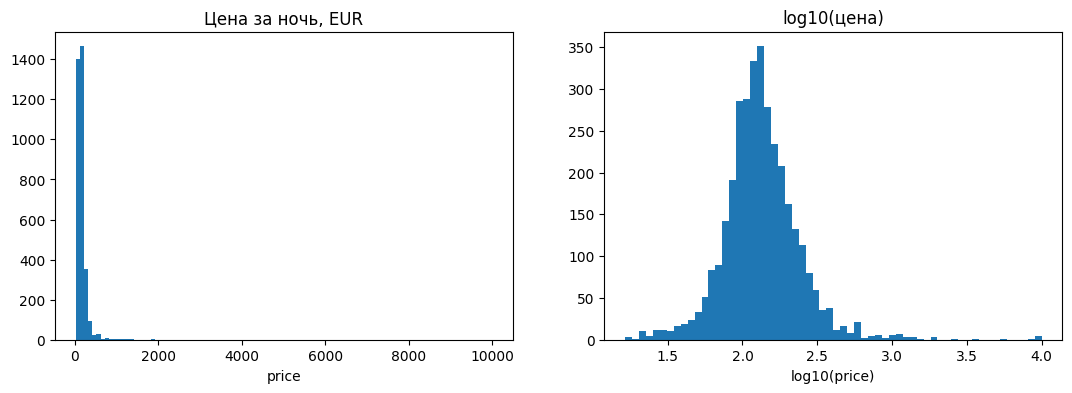

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(data_train['price'], bins=100)
ax[0].set_title('Цена за ночь, EUR'); ax[0].set_xlabel('price')
ax[1].hist(np.log10(data_train['price']), bins=60)
ax[1].set_title('log10(цена)'); ax[1].set_xlabel('log10(price)')
pass

**Распределение цены сильно скошено вправо:** большинство объявлений до 200 €, медиана около 129 €, но встречаются цены до 10 000 € за ночь. Среднее (≈177 €) заметно больше медианы - его тянут вверх редкие очень дорогие объявления. В логарифмической шкале распределение близко к колоколообразному.

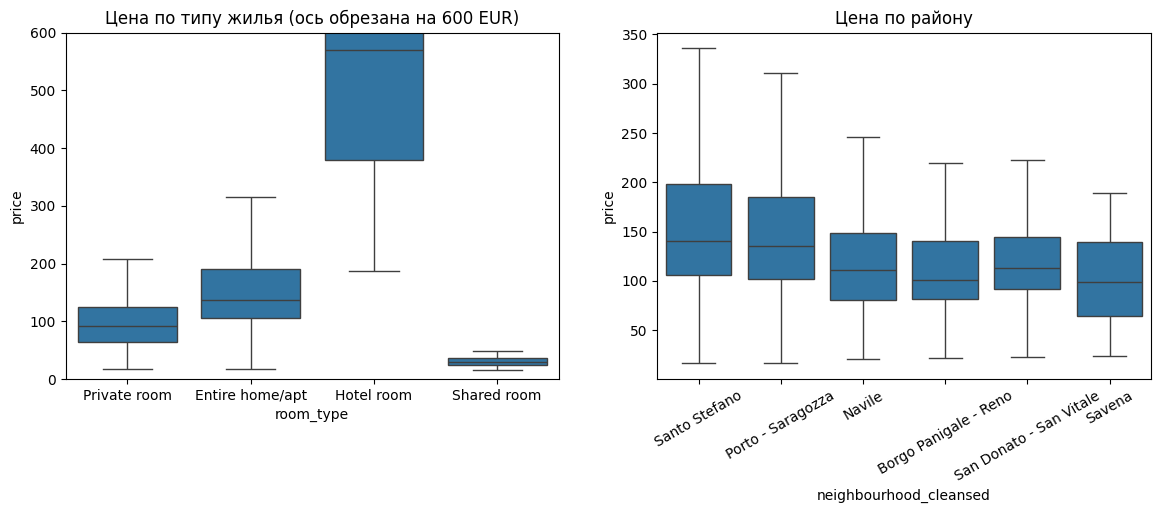

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=data_train, x='room_type', y='price', ax=ax[0], showfliers=False)
ax[0].set_ylim(0, 600)
ax[0].set_title('Цена по типу жилья (ось обрезана на 600 EUR)')
sns.boxplot(data=data_train, x='neighbourhood_cleansed', y='price', ax=ax[1], showfliers=False)
ax[1].set_title('Цена по району'); ax[1].tick_params(axis='x', rotation=30)
pass

- **Тип жилья** сильно влияет на цену: медиана для целой квартиры (`Entire home/apt`) ≈137 €, для комнаты (`Private room`) ≈93 €, для места в общей комнате ≈30 €. `Hotel room` - всего несколько объектов с огромным разбросом, среди них есть явно ошибочные цены.
- **Район:** в центральных районах (`Santo Stefano`, `Porto - Saragozza`) медиана 134-140 €, на окраинах (`Savena`, `Borgo Panigale - Reno`) - около 100 €.

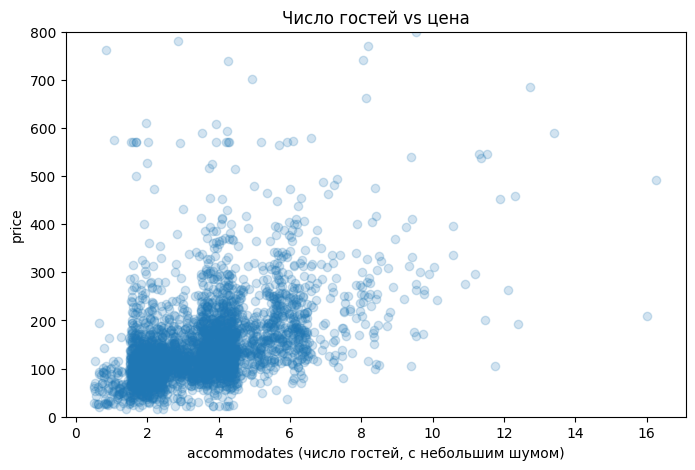

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(data_train['accommodates'] + np.random.rand(len(data_train)) - .5,
            data_train['price'], alpha=0.2)
plt.ylim(0, 800)
plt.xlabel('accommodates (число гостей, с небольшим шумом)'); plt.ylabel('price')
plt.title('Число гостей vs цена')
pass

Цена растёт с числом гостей, но разброс внутри каждой группы очень большой: одна только вместимость цену не определяет.

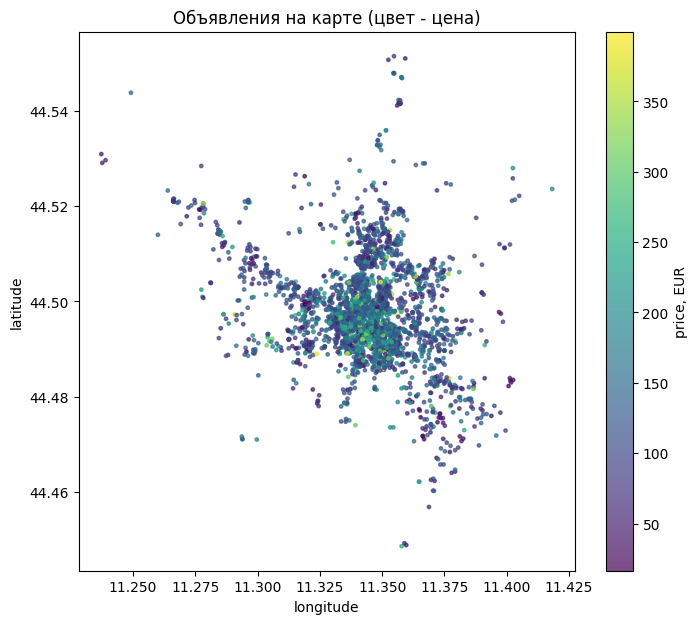

In [12]:
plt.figure(figsize=(8, 7))
d = data_train[data_train['price'] < 400]
plt.scatter(d['longitude'], d['latitude'], c=d['price'], cmap='viridis', s=6, alpha=0.7)
plt.colorbar(label='price, EUR')
plt.xlabel('longitude'); plt.ylabel('latitude'); plt.title('Объявления на карте (цвет - цена)')
pass

На карте видно, что объявления сосредоточены в историческом центре, и дорогих объявлений (светлые точки) там больше. Поэтому координаты - полезные признаки.

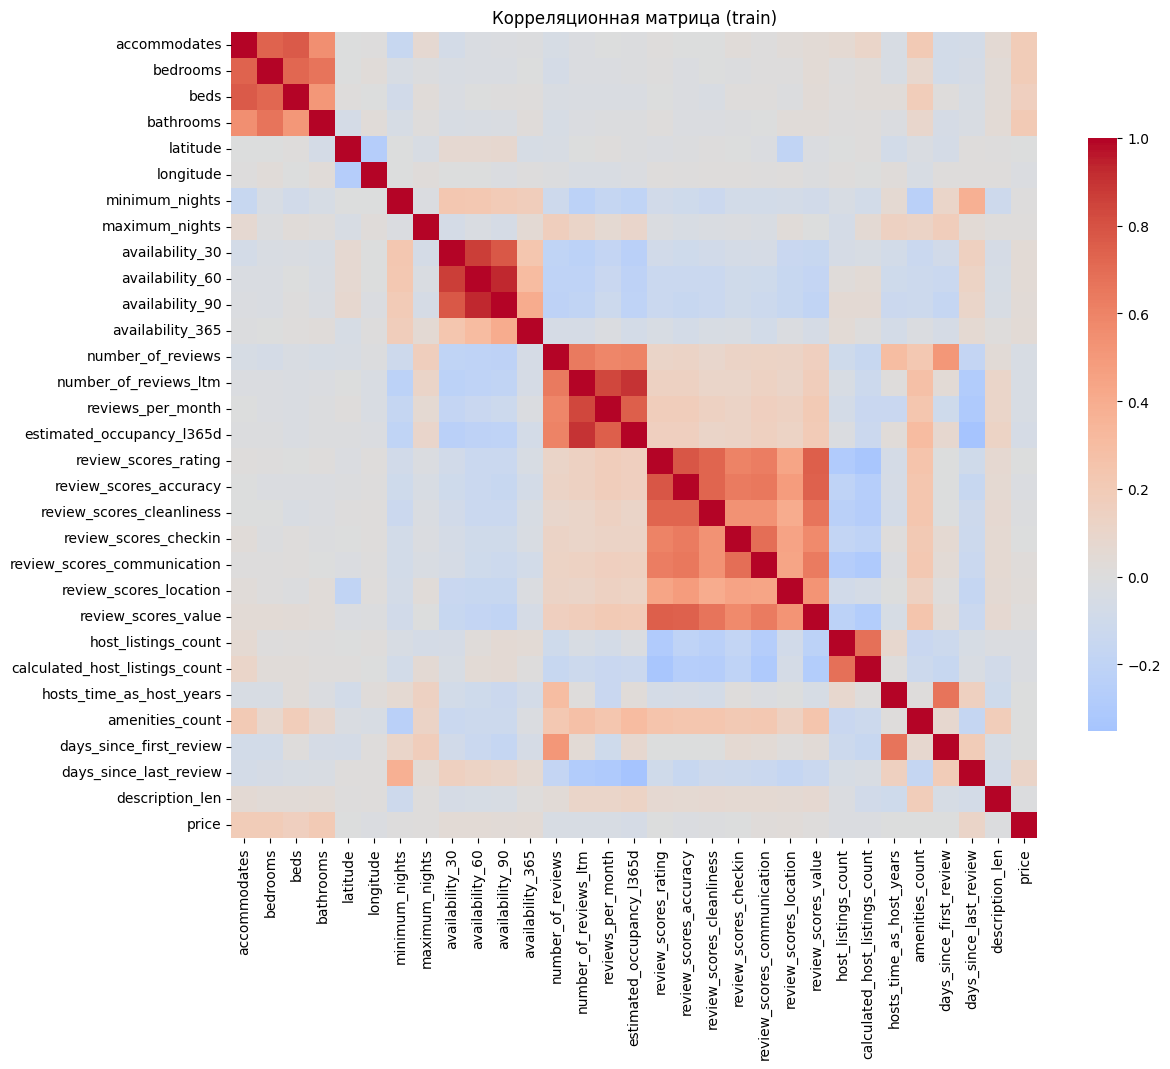

In [13]:
corr = data_train[numerical_columns + ['price']].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': .7})
plt.title('Корреляционная матрица (train)')
pass

In [14]:
corr['price'].drop('price').sort_values(key=abs, ascending=False).head(12).round(3)

,price
bathrooms,0.206
bedrooms,0.188
accommodates,0.187
beds,0.160
days_since_last_review,0.116
estimated_occupancy_l365d,-0.052
availability_60,0.046
availability_30,0.045
reviews_per_month,-0.044
availability_365,0.043


**Корреляционная матрица:**
- Видны группы сильно связанных между собой признаков: доступность на 30/60/90 дней; число отзывов, отзывы за год и оценка занятости; все оценки `review_scores_*`; число гостей, спален и кроватей. К этому вернёмся в п. 12.
- **Линейная корреляция признаков с ценой слабая** (максимум ≈0.2 у числа ванных, спален и гостей). Отчасти виноваты выбросы: несколько цен по 5-10 тыс. € сильно портят коэффициент Пирсона. Кроме того, зависимость нелинейная и проявляется в сочетании признаков (тип жилья + район + размер).

## 4. Выбросы

In [15]:
p = data_train['price']
q1, q3 = p.quantile([0.25, 0.75]); iqr = q3 - q1
print(f'Правило 1.5*IQR: выше {q3 + 1.5*iqr:.0f} EUR лежит {(p > q3 + 1.5*iqr).mean()*100:.1f}% объектов')

price_max = p.quantile(0.99)
print(f'99-й перцентиль цены (train): {price_max:.0f} EUR')
print(data_train[data_train['price'] > price_max][['room_type', 'accommodates', 'bedrooms', 'price']]
      .sort_values('price', ascending=False).head(10))

Правило 1.5*IQR: выше 305 EUR лежит 6.2% объектов
99-й перцентиль цены (train): 840 EUR
            room_type  accommodates  bedrooms     price
2537  Entire home/apt             3       1.0  10000.00
914        Hotel room             4       2.0   9533.53
1772  Entire home/apt             4       1.0   9466.50
4182  Entire home/apt             8       4.0   9129.42
2801  Entire home/apt            16       7.0   9000.00
2486  Entire home/apt             9       3.0   8235.68
326   Entire home/apt             2       1.0   5518.00
1139  Entire home/apt             2       1.0   3664.88
2936  Entire home/apt             6       2.0   2632.00
1083  Entire home/apt             4       1.0   1973.06


По правилу 1.5·IQR выбросами оказываются ≈6% объектов (цены выше ≈300 €). Но среди них много **настоящих** больших квартир на 6-10 гостей, удалять их нельзя - модель должна уметь предсказывать и их.

Поэтому удаляем только самые крайние значения - выше **99-го перцентиля** train (≈840 €). Из таблицы выше видно, что это явные ошибки: например, 10 000 € за ночь за квартиру на 3 гостей. Порог считаем по train и применяем к обеим выборкам.

In [16]:
n_tr, n_te = len(data_train), len(data_test)
data_train = data_train[data_train['price'] <= price_max]
data_test  = data_test[data_test['price'] <= price_max]
print(f'Удалено из train: {n_tr - len(data_train)}, из test: {n_te - len(data_test)}')
print('train:', data_train.shape, ' test:', data_test.shape)

Удалено из train: 35, из test: 12
train: (3373, 38)  test: (1124, 38)


У числовых признаков тоже есть экстремальные значения (минимальный срок аренды 365 дней, хозяин с 722 объявлениями). Для метода ближайших соседей они вредны: после нормализации одно такое значение «растягивает» расстояния. Обрезаем значения признаков по 1-му и 99-му перцентилям train.

In [17]:
# «обрезаем» экстремальные значения числовых признаков по 1-му и 99-му перцентилям train
low  = data_train[numerical_columns].quantile(0.01)
high = data_train[numerical_columns].quantile(0.99)
data_train[numerical_columns] = data_train[numerical_columns].clip(low, high, axis=1)
data_test[numerical_columns]  = data_test[numerical_columns].clip(low, high, axis=1)
data_train[['minimum_nights', 'maximum_nights', 'host_listings_count']].describe().round(1)

,minimum_nights,maximum_nights,host_listings_count
count,3370.0,3370.0,3367.0
mean,4.0,547.6,24.3
std,8.3,465.8,54.3
min,1.0,7.0,1.0
25%,1.0,40.0,1.0
50%,1.0,365.0,4.0
75%,2.0,1125.0,21.0
max,31.0,1125.0,360.0


## 5. Пропущенные значения

In [18]:
na = data_train.isna().mean().mul(100).round(1)
na[na > 0].sort_values(ascending=False)

,0
bedrooms,17.9
review_scores_rating,9.7
days_since_last_review,9.7
reviews_per_month,9.7
review_scores_cleanliness,9.7
review_scores_accuracy,9.7
review_scores_checkin,9.7
review_scores_communication,9.7
review_scores_value,9.7
review_scores_location,9.7


- `bedrooms` (≈18%), `beds` (≈5%) - хозяин не указал; заполняем **медианой train**.
- Группа признаков об отзывах пропущена у одних и тех же ≈10% объявлений: у них **ещё нет ни одного отзыва**. Пропуск здесь - это информация, поэтому добавляем флаг `no_reviews`, а сами значения заполняем медианой.
- Категориальные признаки (пропусков доли процента) заполняем самым частым значением.

In [19]:
# флаг «нет отзывов»: пропуск в рейтингах означает именно это
for df_ in (data_train, data_test):
    df_['no_reviews'] = df_['review_scores_rating'].isna().astype(int)

medians = data_train[numerical_columns].median()
data_train[numerical_columns] = data_train[numerical_columns].fillna(medians)
data_test[numerical_columns]  = data_test[numerical_columns].fillna(medians)

modes = data_train[categorical_columns].mode().iloc[0]
data_train[categorical_columns] = data_train[categorical_columns].fillna(modes)
data_test[categorical_columns]  = data_test[categorical_columns].fillna(modes)

print('Пропусков в train:', data_train.isna().sum().sum(), ' в test:', data_test.isna().sum().sum())

Пропусков в train: 0  в test: 0


## 6. Категориальные признаки

In [20]:
binary_columns    = [c for c in categorical_columns if data_train[c].nunique() == 2]
nonbinary_columns = [c for c in categorical_columns if data_train[c].nunique() > 2]
print('бинарные:', binary_columns)
print('небинарные:', nonbinary_columns)
for c in nonbinary_columns:
    print(c, data_train[c].unique())

бинарные: ['bath_shared', 'host_is_superhost', 'host_identity_verified', 'has_availability']
небинарные: ['room_type', 'neighbourhood_cleansed', 'property_type']
room_type ['Private room' 'Entire home/apt' 'Hotel room' 'Shared room']
neighbourhood_cleansed ['Santo Stefano' 'Porto - Saragozza' 'Navile' 'Borgo Panigale - Reno'
 'San Donato - San Vitale' 'Savena']
property_type ['Private room in vacation home' 'Entire rental unit' 'Entire condo'
 'Private room in rental unit' 'Other' 'Entire vacation home'
 'Private room in bed and breakfast' 'Private room in condo' 'Entire home']


- **Бинарные** (`t`/`f`) переводим в 0/1.
- **Небинарные** (`room_type`, `neighbourhood_cleansed`, `property_type`) векторизуем (one-hot): признак с `s` значениями заменяется на `s` признаков 0/1. Столбцы теста приводим к столбцам train.

In [21]:
for c in binary_columns:
    for df_ in (data_train, data_test):
        df_[c] = (df_[c] == 't').astype(int)

dummies_train = pd.get_dummies(data_train[nonbinary_columns], dtype=int)
dummies_test  = pd.get_dummies(data_test[nonbinary_columns], dtype=int)
dummies_test  = dummies_test.reindex(columns=dummies_train.columns, fill_value=0)
print('one-hot признаков:', dummies_train.shape[1])

one-hot признаков: 19


## 7. Нормализация

Нормализация **нужна**: метод ближайших соседей считает евклидово расстояние, и без неё признаки с большим масштабом полностью доминировали бы. Например, `maximum_nights` меняется от 1 до 1125, а оценки `review_scores_*` - от 0 до 5. Приводим числовые признаки к нулевому среднему и единичному стандартному отклонению; среднее и std считаем по train.

In [22]:
num_cols = numerical_columns + ['no_reviews']
mean = data_train[num_cols].mean()
std  = data_train[num_cols].std()

num_train = (data_train[num_cols] - mean) / std
num_test  = (data_test[num_cols]  - mean) / std
num_train.describe().loc[['mean', 'std']].round(2)

,accommodates,bedrooms,beds,bathrooms,latitude,longitude,minimum_nights,maximum_nights,availability_30,availability_60,...,review_scores_location,review_scores_value,host_listings_count,calculated_host_listings_count,hosts_time_as_host_years,amenities_count,days_since_first_review,days_since_last_review,description_len,no_reviews
mean,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,...,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [23]:
X_train = pd.concat((num_train, dummies_train, data_train[binary_columns]), axis=1)
X_test  = pd.concat((num_test,  dummies_test,  data_test[binary_columns]),  axis=1)
y_train = data_train['price'].to_numpy()
y_test  = data_test['price'].to_numpy()
feature_names = X_train.columns
X_train, X_test = X_train.to_numpy(), X_test.to_numpy()
print(X_train.shape, X_test.shape)

(3373, 54) (1124, 54)


## 8. Метод k ближайших соседей

In [24]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(model, name):
    rows = []
    for part, X, y in (('train', X_train, y_train), ('test', X_test, y_test)):
        pred = model.predict(X)
        rows.append([name, part, mean_absolute_error(y, pred),
                     np.sqrt(mean_squared_error(y, pred)), r2_score(y, pred)])
    return pd.DataFrame(rows, columns=['model', 'sample', 'MAE', 'RMSE', 'R2']).round(3)

knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_train, y_train)
report(knn, 'kNN, k=10')

,model,sample,MAE,RMSE,R2
0,"kNN, k=10",train,40.578,65.164,0.474
1,"kNN, k=10",test,46.519,77.883,0.320


In [25]:
# для сравнения: «модель», которая всегда предсказывает медиану цены train
base = np.full_like(y_test, np.median(y_train), dtype=float)
print(f'Константа (медиана): MAE на test = {mean_absolute_error(y_test, base):.1f} EUR, R2 = {r2_score(y_test, base):.3f}')

Константа (медиана): MAE на test = 57.5 EUR, R2 = -0.059


## 9. Ошибки на обучающей и тестовой выборках, подбор k

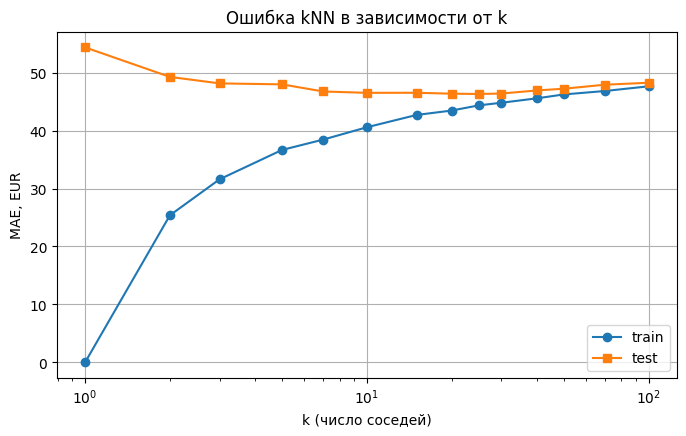

In [26]:
ks = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 40, 50, 70, 100]
mae_train, mae_test = [], []
for k in ks:
    m = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    mae_train.append(mean_absolute_error(y_train, m.predict(X_train)))
    mae_test.append(mean_absolute_error(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 4.5))
plt.plot(ks, mae_train, 'o-', label='train')
plt.plot(ks, mae_test, 's-', label='test')
plt.xscale('log'); plt.xlabel('k (число соседей)'); plt.ylabel('MAE, EUR')
plt.title('Ошибка kNN в зависимости от k'); plt.legend(); plt.grid()
pass

- При **k = 1** ошибка на train нулевая (каждая точка - сама себе ближайший сосед), а на test максимальная (≈54 €): модель **переобучена**.
- С ростом k ошибка на train растёт, а на test сначала падает, потом снова растёт: при больших k модель усредняет слишком много далёких соседей и **недообучается**.
- Минимум ошибки на test - в районе k = 10-30.

Подбирать k по тестовой выборке нельзя (тест тогда перестаёт быть честной проверкой), поэтому выбираем k **кросс-валидацией** на train (5 фолдов):

In [27]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(KNeighborsRegressor(), param_grid={'n_neighbors': ks},
                    cv=5, scoring='neg_mean_absolute_error')
grid.fit(X_train, y_train)
best_k = grid.best_params_['n_neighbors']
print('Лучшее k по кросс-валидации:', best_k, '  CV MAE =', round(-grid.best_score_, 2))

Лучшее k по кросс-валидации: 7   CV MAE = 45.7


In [28]:
knn = KNeighborsRegressor(n_neighbors=best_k).fit(X_train, y_train)
res_knn = report(knn, f'kNN, k={best_k}')
res_knn

,model,sample,MAE,RMSE,R2
0,"kNN, k=7",train,38.451,62.249,0.520
1,"kNN, k=7",test,46.750,78.629,0.307


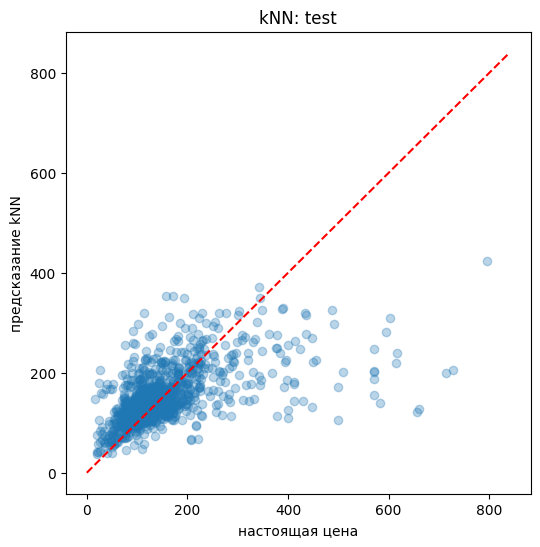

In [29]:
pred = knn.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([0, price_max], [0, price_max], 'r--')
plt.xlabel('настоящая цена'); plt.ylabel('предсказание kNN'); plt.title('kNN: test')
pass

**Итог kNN:** MAE на test ≈47 €, R² ≈0.31. Для сравнения, константное предсказание (медиана) даёт MAE ≈57.5 € и R² ≈0, так что модель работает заметно лучше.

Разрыв train/test небольшой (≈38 € против ≈47 €) - сильного переобучения нет. На графике видно, что дешёвые и средние объявления предсказываются неплохо, а дорогие (> 300 €) модель систематически **недооценивает**: таких объектов мало, и у дорогой квартиры среди ближайших соседей оказываются в основном обычные.

## 10. Другие модели

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

lr  = LinearRegression().fit(X_train, y_train)
rf  = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(X_train, y_train)
gbt = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train, y_train)

results = pd.concat([res_knn, report(lr, 'Linear Regression'),
                     report(rf, 'Random Forest'), report(gbt, 'Gradient Boosting')])
results.pivot(index='model', columns='sample', values=['MAE', 'R2']).sort_values(('MAE', 'test'))

MAE             R2       
sample               test   train   test  train
model                                          
Gradient Boosting  41.399  22.008  0.449  0.881
Random Forest      43.000  18.005  0.408  0.861
Linear Regression  44.406  43.035  0.403  0.409
kNN, k=7           46.750  38.451  0.307  0.520

- **Gradient Boosting** - лучший результат на test (MAE ≈41 €, R² ≈0.45), **Random Forest** - близко к нему.
- Леса и бустинг заметно переобучаются (на train ошибка 18-22 €, на test 41-43 €), но на test всё равно лучше остальных.
- **Линейная регрессия** неожиданно обошла kNN: основная зависимость цены от размера жилья близка к линейной (больше комнат и гостей → дороже).
- **kNN - худший** из четырёх. Причина: в расстоянии все 54 признака имеют одинаковый вес, хотя большинство из них на цену почти не влияет (*проклятие размерности*). Деревья сами выбирают важные признаки.

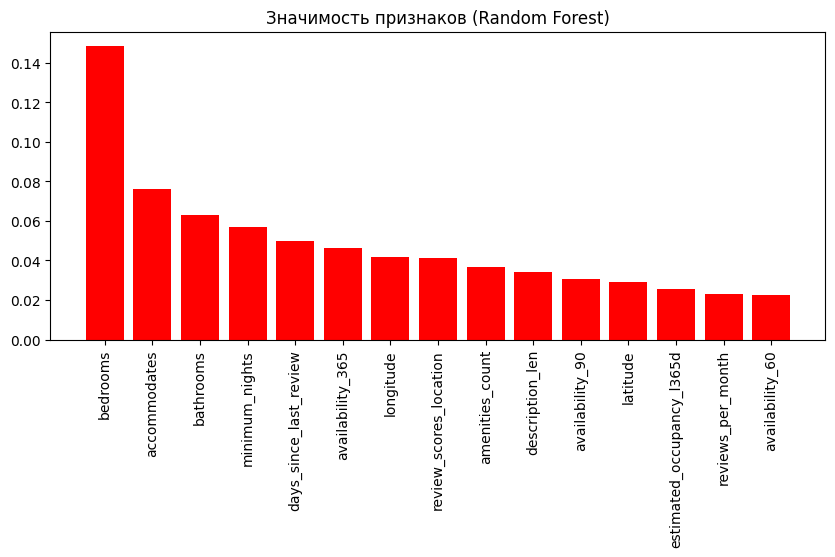

In [31]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
d_first = 15
plt.figure(figsize=(10, 4))
plt.bar(range(d_first), importances[indices[:d_first]], color='r')
plt.xticks(range(d_first), feature_names[indices[:d_first]], rotation=90)
plt.title('Значимость признаков (Random Forest)')
pass

Самые важные признаки - размер жилья (`bedrooms`, `accommodates`, `bathrooms`), минимальный срок аренды, давность последнего отзыва, доступность в календаре и координаты. Это согласуется с выводами п. 3.

## 11. Несбалансированность классов

Не применимо: решается задача регрессии, классов нет.

## 12. Исключение коррелированных признаков

Сильно коррелированные признаки почти дублируют друг друга. Для kNN это плохо: дублирующаяся информация входит в расстояние дважды и получает лишний вес. Ищем пары с |r| > 0.85 (по train) и удаляем один признак из каждой пары.

In [32]:
c = pd.DataFrame(num_train, columns=num_cols).corr().abs()
upper = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))
pairs = upper.stack()
pairs = pairs[pairs > 0.85].sort_values(ascending=False)
print(pairs.round(3))
to_drop = sorted({b for a, b in pairs.index})
print('\nУдаляем:', to_drop)

number_of_reviews_ltm  estimated_occupancy_l365d    0.933
availability_60        availability_90              0.929
availability_30        availability_60              0.861
dtype: float64

Удаляем: ['availability_60', 'availability_90', 'estimated_occupancy_l365d']


In [33]:
keep = [i for i, f in enumerate(feature_names) if f not in to_drop]
X_train_r, X_test_r = X_train[:, keep], X_test[:, keep]

grid_r = GridSearchCV(KNeighborsRegressor(), param_grid={'n_neighbors': ks},
                      cv=5, scoring='neg_mean_absolute_error').fit(X_train_r, y_train)
k_r = grid_r.best_params_['n_neighbors']
knn_r = KNeighborsRegressor(n_neighbors=k_r).fit(X_train_r, y_train)

rows = []
for part, X, y in (('train', X_train_r, y_train), ('test', X_test_r, y_test)):
    p_ = knn_r.predict(X)
    rows.append([f'kNN без коррелированных, k={k_r}', part, mean_absolute_error(y, p_),
                 np.sqrt(mean_squared_error(y, p_)), r2_score(y, p_)])
res_r = pd.DataFrame(rows, columns=['model', 'sample', 'MAE', 'RMSE', 'R2']).round(3)
print('признаков было', X_train.shape[1], ', стало', X_train_r.shape[1])
pd.concat([res_knn, res_r])

признаков было 54 , стало 51


,model,sample,MAE,RMSE,R2
0,"kNN, k=7",train,38.451,62.249,0.520
1,"kNN, k=7",test,46.750,78.629,0.307
0,"kNN без коррелированных, k=10",train,40.407,65.353,0.471
1,"kNN без коррелированных, k=10",test,45.980,77.677,0.324


После удаления трёх дублирующих признаков ошибка kNN на test немного уменьшилась (MAE ≈46.0 € вместо ≈46.8 €, R² 0.32 вместо 0.31). Эффект небольшой, но в ожидаемую сторону: модель стала проще, а качество не ухудшилось.

## 13. Выводы

1. Датасет - 4948 объявлений Airbnb в Болонье; после удаления объявлений без цены и явно ошибочных цен осталось ≈4500. Решалась задача регрессии - предсказание цены за ночь.
2. Данные потребовали серьёзной подготовки: 13 пустых и служебных столбцов, пропуски (особенно `bedrooms` и признаки отзывов), выбросы в цене до 10 000 €, категориальные признаки, текст и даты, которые пришлось превратить в числа.
3. Цена сильнее всего зависит от размера жилья (спальни, гости, ванные), типа жилья и расположения: в центре дороже.
4. **kNN** с подобранным кросс-валидацией k = 7 даёт MAE ≈47 € и R² ≈0.31 - лучше константы (MAE ≈57.5 €), но хуже остальных моделей. Нормализация для kNN обязательна; удаление коррелированных признаков немного улучшает результат.
5. Лучший результат у **градиентного бустинга**: MAE ≈41 €, R² ≈0.45.
6. Даже лучшая модель объясняет меньше половины разброса цены. Часть информации в данных просто отсутствует (качество ремонта, вид из окна, фотографии), а дорогие объявления предсказываются плохо из-за их малого числа. Возможные улучшения: предсказывать логарифм цены, использовать текст описания (TF-IDF), отобрать признаки для kNN.